In [1]:
import pandas as pd

In [2]:
# Load the uploaded dataset with uncommon name "uk_house"
file_path = "UK_House_Price_Prediction_dataset_2015_to_2024.csv"
uk_house = pd.read_csv(file_path)

In [3]:
# Get basic info about the dataset
uk_house_info = {
    "shape": uk_house.shape,
    "columns": uk_house.columns.tolist(),
    "head": uk_house.head(10)
}

uk_house_info

{'shape': (90000, 11),
 'columns': ['price',
  'date',
  'postcode',
  'property_type',
  'new_build',
  'freehold',
  'street',
  'locality',
  'town',
  'district',
  'county'],
 'head':     price        date  postcode property_type new_build freehold  \
 0  735000  2017-08-07  LE17 5AP             D         N        F   
 1  160000  2023-02-03  SA11 4BD             T         N        F   
 2  176500  2015-01-06   ME3 0DQ             S         N        F   
 3  625000  2021-10-13  RH20 3EU             D         N        F   
 4  202000  2019-09-27  SN13 8EN             S         N        F   
 5  249950  2019-09-06  LS12 5FA             S         Y        F   
 6  730000  2018-11-16   BA1 9AU             D         Y        F   
 7  185000  2023-12-18  NR10 5PB             S         N        F   
 8  120000  2021-11-10  WS12 1DN             T         N        L   
 9  124000  2017-12-08  HU12 8BZ             T         N        F   
 
               street          locality         tow

In [4]:
# Check for missing or null values in the dataset
missing_values = uk_house.isnull().sum()

missing_values_summary = missing_values[missing_values > 0]
missing_values_summary

Series([], dtype: int64)

In [5]:
from sklearn.preprocessing import LabelEncoder

In [6]:
# Copy dataset for preprocessing
uk_house_clean = uk_house.copy()

# Convert date to datetime and extract year and month
uk_house_clean['date'] = pd.to_datetime(uk_house_clean['date'], errors='coerce')
uk_house_clean['year'] = uk_house_clean['date'].dt.year
uk_house_clean['month'] = uk_house_clean['date'].dt.month

# Drop the original 'date' column as year and month are more useful
uk_house_clean = uk_house_clean.drop(columns=['date'])

In [7]:
# Simple binary mappings for new_build and freehold
uk_house_clean['new_build'] = uk_house_clean['new_build'].map({'Y': 1, 'N': 0})
uk_house_clean['freehold'] = uk_house_clean['freehold'].map({'F': 1, 'L': 0})  # Freehold=1, Leasehold=0

# Label encode high-cardinality features: property_type, postcode, street, locality, town, district, county
categorical_cols = ['property_type', 'postcode', 'street', 'locality', 'town', 'district', 'county']
label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    uk_house_clean[col] = le.fit_transform(uk_house_clean[col].astype(str))
    label_encoders[col] = le

In [8]:
cleaned_shape = uk_house_clean.shape
cleaned_head = uk_house_clean.head()

(cleaned_shape, cleaned_head)

((90000, 12),
     price  postcode  property_type  new_build  freehold  street  locality  \
 0  735000     30844              0          0         1    8382      1929   
 1  160000     58602              4          0         1   15902      5815   
 2  176500     37621              3          0         1   16311      4665   
 3  625000     55658              0          0         1   22938      8714   
 4  202000     62034              3          0         1    8720      1037   
 
    town  district  county  year  month  
 0   511       136      54  2017      8  
 1   574       192      63  2023      2  
 2   687       180      57  2015      1  
 3   666       150     107  2021     10  
 4   225       343     110  2019      9  )

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

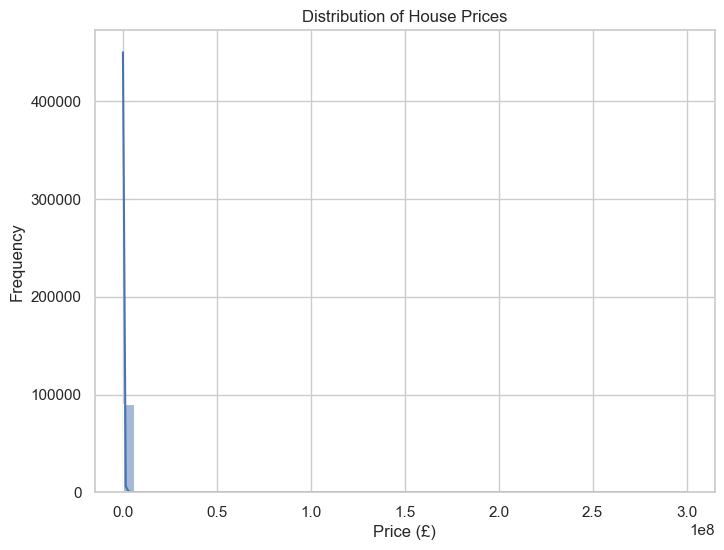

In [10]:
# Set visualization style
sns.set(style="whitegrid")

# Distribution of House Prices
plt.figure(figsize=(8,6))
sns.histplot(uk_house_clean['price'], bins=50, kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")
plt.show()

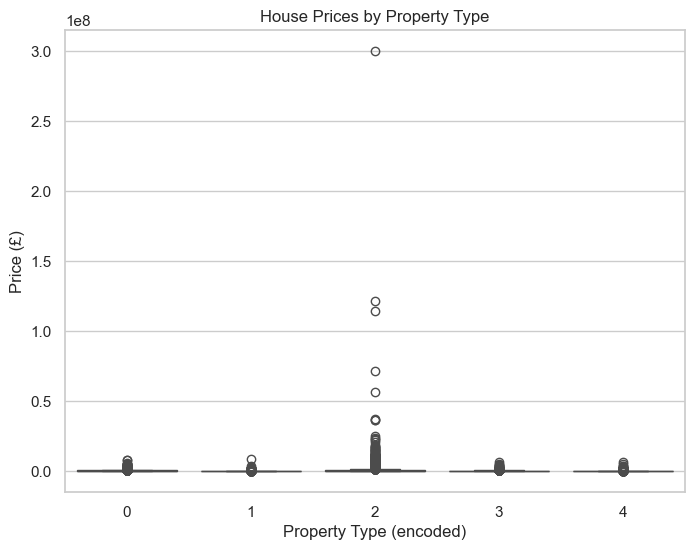

In [11]:
# Average House Price by Property Type
plt.figure(figsize=(8,6))
sns.boxplot(x='property_type', y='price', data=uk_house_clean)
plt.title("House Prices by Property Type")
plt.xlabel("Property Type (encoded)")
plt.ylabel("Price (£)")
plt.show()

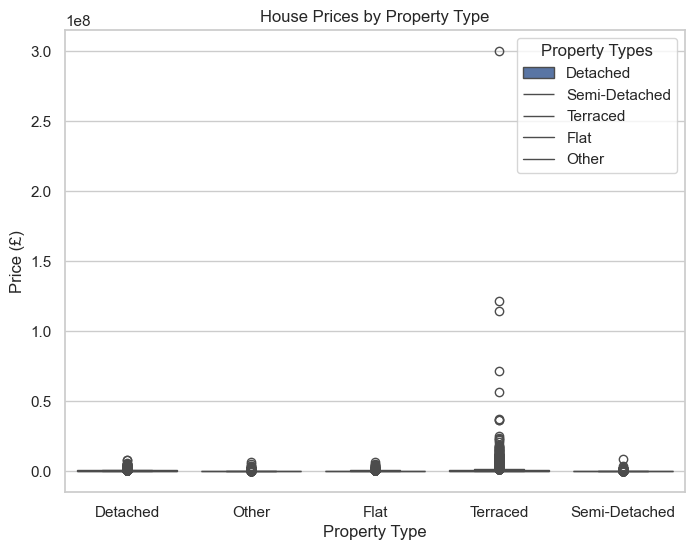

In [12]:
# Average House Price by Property Type with labels
plt.figure(figsize=(8,6))

# Mapping encoded property types to meaningful labels
property_labels = {
    0: "Detached",
    1: "Semi-Detached",
    2: "Terraced",
    3: "Flat",
    4: "Other"
}
uk_house_clean['property_type_label'] = uk_house_clean['property_type'].map(property_labels)

# Boxplot with proper labels
sns.boxplot(x='property_type_label', y='price', data=uk_house_clean)

plt.title("House Prices by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Price (£)")

# Add legend for clarity
plt.legend(title="Property Types", labels=property_labels.values(), loc="upper right")

plt.show()

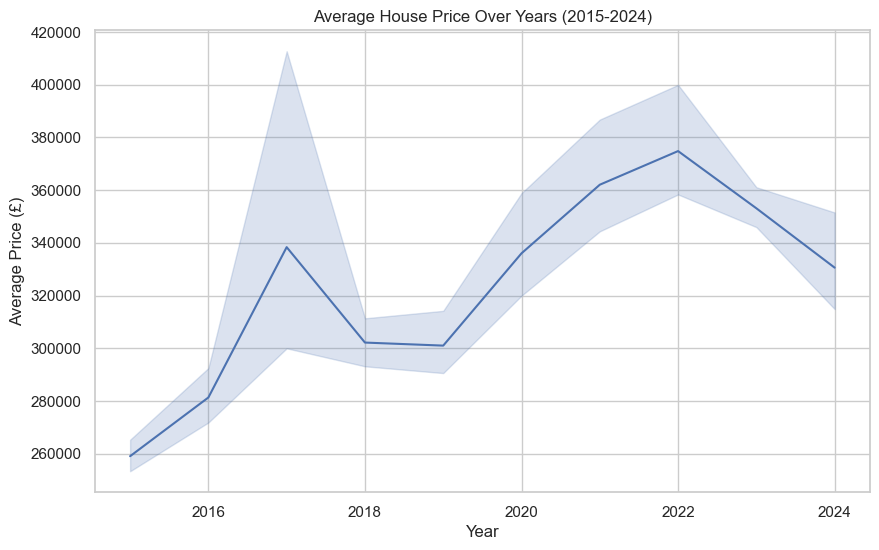

In [13]:
# Average House Price by Year
plt.figure(figsize=(10,6))
sns.lineplot(x='year', y='price', data=uk_house_clean, estimator='mean')
plt.title("Average House Price Over Years (2015-2024)")
plt.xlabel("Year")
plt.ylabel("Average Price (£)")
plt.show()

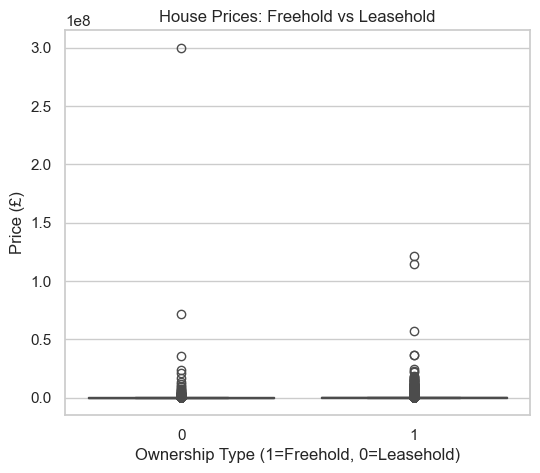

In [14]:
# Impact of Freehold vs Leasehold on Prices
plt.figure(figsize=(6,5))
sns.boxplot(x='freehold', y='price', data=uk_house_clean)
plt.title("House Prices: Freehold vs Leasehold")
plt.xlabel("Ownership Type (1=Freehold, 0=Leasehold)")
plt.ylabel("Price (£)")
plt.show()

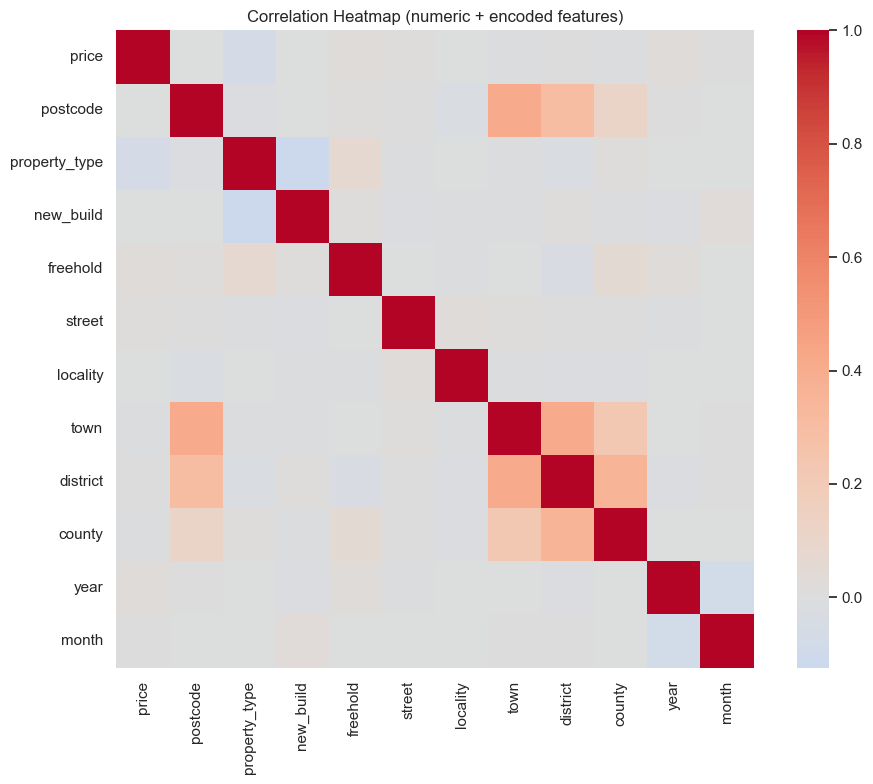

In [15]:
# Correlation Heatmap of Features
df_corr = uk_house_clean.copy()

# encode property_type only (add others if truly meaningful for corr)
if df_corr['property_type'].dtype == 'object':
    df_corr['property_type_code'] = df_corr['property_type'].astype('category').cat.codes

num_cols = df_corr.select_dtypes(include=[np.number]).columns
corr = df_corr[num_cols].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, cmap='coolwarm', center=0, square=True)
plt.title("Correlation Heatmap (numeric + encoded features)")
plt.tight_layout()
plt.show()

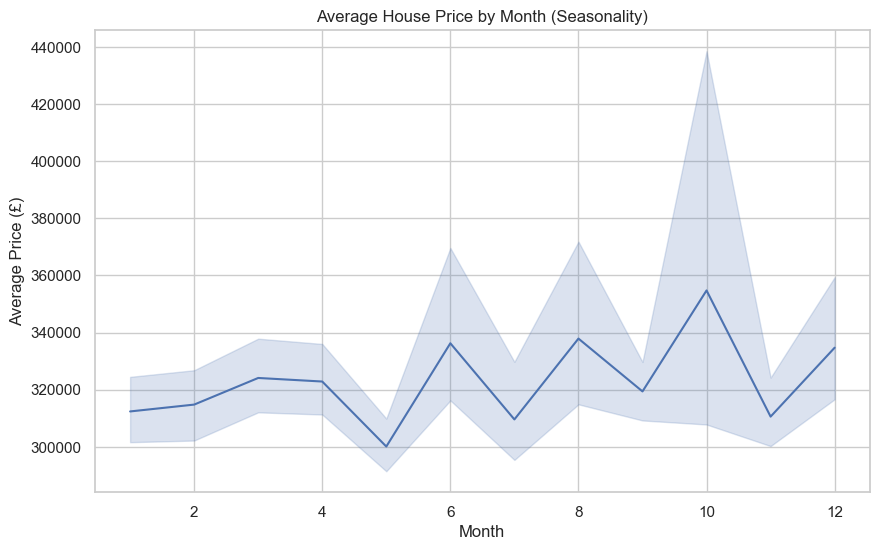

In [16]:
# Average House Price by Month (seasonal trend)
plt.figure(figsize=(10,6))
sns.lineplot(x='month', y='price', data=uk_house_clean, estimator='mean')
plt.title("Average House Price by Month (Seasonality)")
plt.xlabel("Month")
plt.ylabel("Average Price (£)")
plt.show()

In [17]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

In [18]:
X = uk_house_clean.drop(columns=['price']).copy()
y = pd.to_numeric(uk_house_clean['price'], errors='coerce')  # ensure numeric
X = X.loc[y.notna()]
y = y.loc[y.notna()]

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [20]:
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]

# (handles unseen categories at test time; works across sklearn versions)
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

pre = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', ohe, cat_cols)
    ],
    remainder='drop'
)


In [21]:
lin_pipe = Pipeline(steps=[
    ('prep', pre),
    ('reg', LinearRegression())
])

lin_pipe.fit(X_train, y_train)
y_pred_lr = lin_pipe.predict(X_test)

model_results = {}
model_results['Linear Regression'] = {
    "RMSE": float(np.sqrt(mean_squared_error(y_test, y_pred_lr))),
    "MAE":  float(mean_absolute_error(y_test, y_pred_lr)),
    "R2":   float(r2_score(y_test, y_pred_lr))
}

print(model_results['Linear Regression'])

{'RMSE': 581571.4079255376, 'MAE': 160781.2852985192, 'R2': 0.05819103611192955}


In [22]:
# Random Forest Regressor 
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]

# One-hot encoder (handles unseen categories at test time)
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:  # for older sklearn
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

pre = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', ohe, cat_cols)
    ],
    remainder='drop'
)

# Random Forest Regressor (with preprocessing)
rf_pipe = Pipeline(steps=[
    ('prep', pre),
    ('reg', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

# Optional: train on a 20k sample to speed up
if len(X_train) > 20000:
    idx = X_train.sample(n=20000, random_state=42).index
    rf_pipe.fit(X_train.loc[idx], y_train.loc[idx])
else:
    rf_pipe.fit(X_train, y_train)

# Predict & metrics
y_pred_rf = rf_pipe.predict(X_test)

model_results['Random Forest'] = {
    "RMSE": float(np.sqrt(mean_squared_error(y_test, y_pred_rf))),
    "MAE":  float(mean_absolute_error(y_test, y_pred_rf)),
    "R2":   float(r2_score(y_test, y_pred_rf))
}

print(model_results['Random Forest'])

{'RMSE': 862856.6918090864, 'MAE': 146250.93504984918, 'R2': -1.0731659576106}


In [23]:
# Identify column types from current split
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]

# Robust OHE (compatible with older sklearn)
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

pre = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', ohe, cat_cols)
    ],
    remainder='drop'
)

# Gradient Boosting with preprocessing
gb_pipe = Pipeline(steps=[
    ('prep', pre),
    ('reg', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ))
])

# Optional: fit on a 20k sample for speed
if len(X_train) > 20000:
    idx = X_train.sample(n=20000, random_state=42).index
    gb_pipe.fit(X_train.loc[idx], y_train.loc[idx])
else:
    gb_pipe.fit(X_train, y_train)

# Predict and metrics
y_pred_gb = gb_pipe.predict(X_test)

model_results['Gradient Boosting'] = {
    "RMSE": float(np.sqrt(mean_squared_error(y_test, y_pred_gb))),
    "MAE":  float(mean_absolute_error(y_test, y_pred_gb)),
    "R2":   float(r2_score(y_test, y_pred_gb))
}

print(model_results['Gradient Boosting'])

{'RMSE': 1310523.8615833686, 'MAE': 154374.4185448319, 'R2': -3.7824076392180093}


In [24]:
# Convert results into DataFrame 
results_df = pd.DataFrame(model_results).T
print(results_df)

                           RMSE            MAE        R2
Linear Regression  5.815714e+05  160781.285299  0.058191
Random Forest      8.628567e+05  146250.935050 -1.073166
Gradient Boosting  1.310524e+06  154374.418545 -3.782408


In [25]:
import shap
import lime.lime_tabular
import numpy as np
import matplotlib.pyplot as plt

In [26]:
model = gb_pipe  

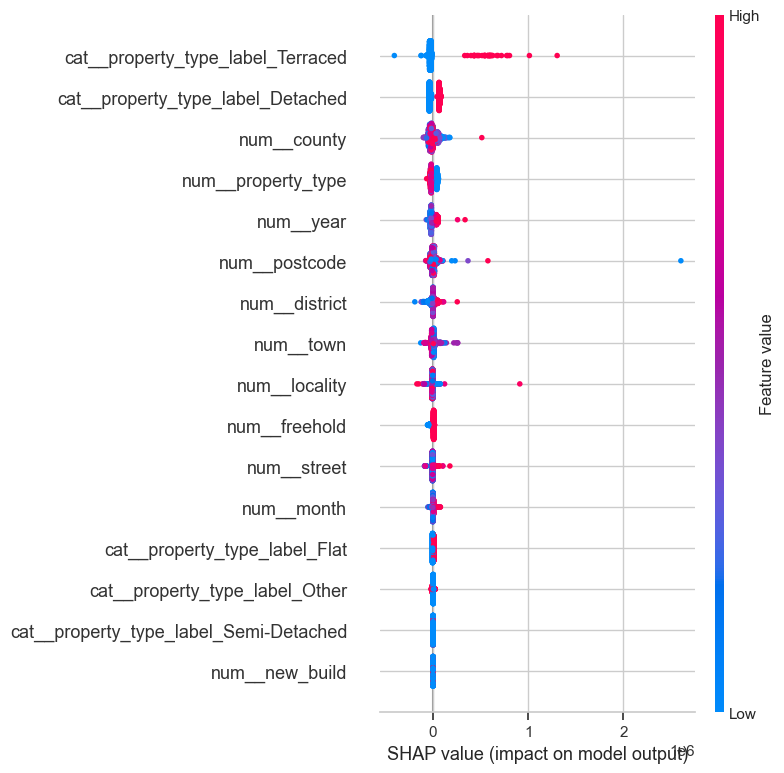

In [27]:
# Get the final regressor (last step in pipeline)
final_model = model.named_steps['reg']

# Use TreeExplainer directly
explainer_shap = shap.TreeExplainer(final_model)

# IMPORTANT: use transformed features (after preprocessing)
X_transformed = model.named_steps['prep'].transform(X_test[:1000])
feature_names = model.named_steps['prep'].get_feature_names_out()

shap_values = explainer_shap.shap_values(X_transformed)
shap.summary_plot(shap_values, X_transformed, feature_names=feature_names)

In [28]:
# Grab the preprocessor and the final regressor from the pipeline
preproc = model.named_steps['prep']
final_reg = model.named_steps['reg']   # the estimator after preprocessing

# Transform train/test with the SAME preprocessor used in the pipeline
X_train_trans = preproc.transform(X_train)
X_test_trans  = preproc.transform(X_test)

# Get feature names after preprocessing (works across sklearn versions)
try:
    feat_names = preproc.get_feature_names_out()
except AttributeError:
    # fallback if using older scikit-learn
    feat_names = np.array([f'feat_{i}' for i in range(X_train_trans.shape[1])])

# Build the LIME explainer on the **transformed numeric** training data
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.asarray(X_train_trans),
    feature_names=feat_names,
    mode="regression",
    discretize_continuous=True,   # typical for tabular regression
    kernel_width=3.0
)

# Explain ONE transformed test instance
i = 5  # pick any test index you like
instance = np.asarray(X_test_trans[i])

# The final regressor, not the whole pipeline.
exp = explainer_lime.explain_instance(
    data_row=instance,
    predict_fn=final_reg.predict,
    num_features=10
)

# Display
exp.show_in_notebook(show_table=True)
print(exp.as_list())

[('cat__property_type_label_Terraced <= 0.00', -491868.1344307285), ('0.00 < cat__property_type_label_Detached <= 1.00', 117671.61439104794), ('num__property_type <= 0.00', 59712.94480732004), ('37.00 < num__county <= 55.00', 36775.110926683585), ('num__district > 265.00', 35572.278998235226), ('num__year > 2021.00', 26330.8348260256), ('num__new_build <= 0.00', 24543.79206753409), ('2510.00 < num__locality <= 4948.00', -22850.38293614694), ('cat__property_type_label_Other <= 0.00', 17302.399997943732), ('cat__property_type_label_Semi-Detached <= 0.00', 13716.805971223524)]


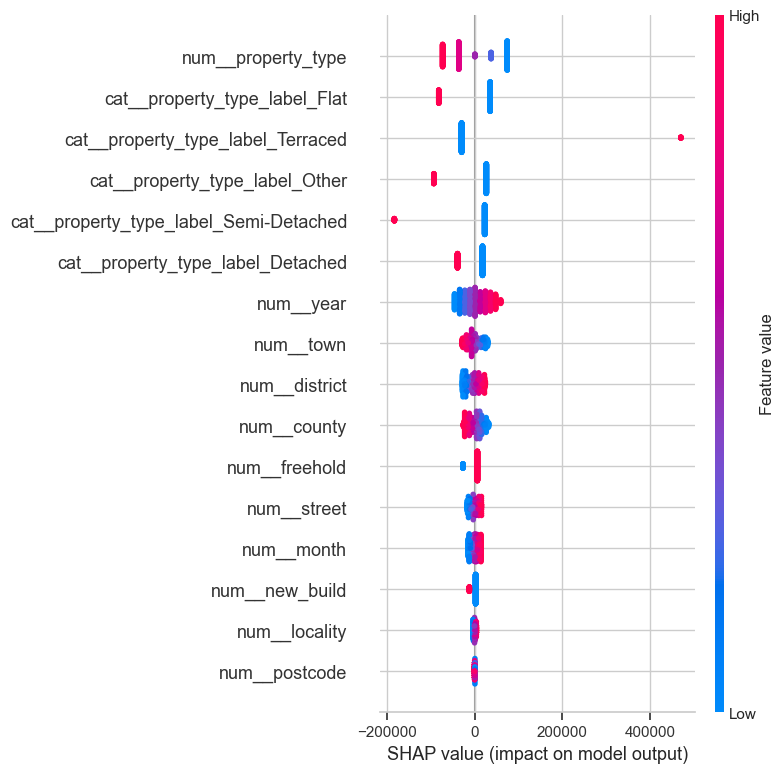

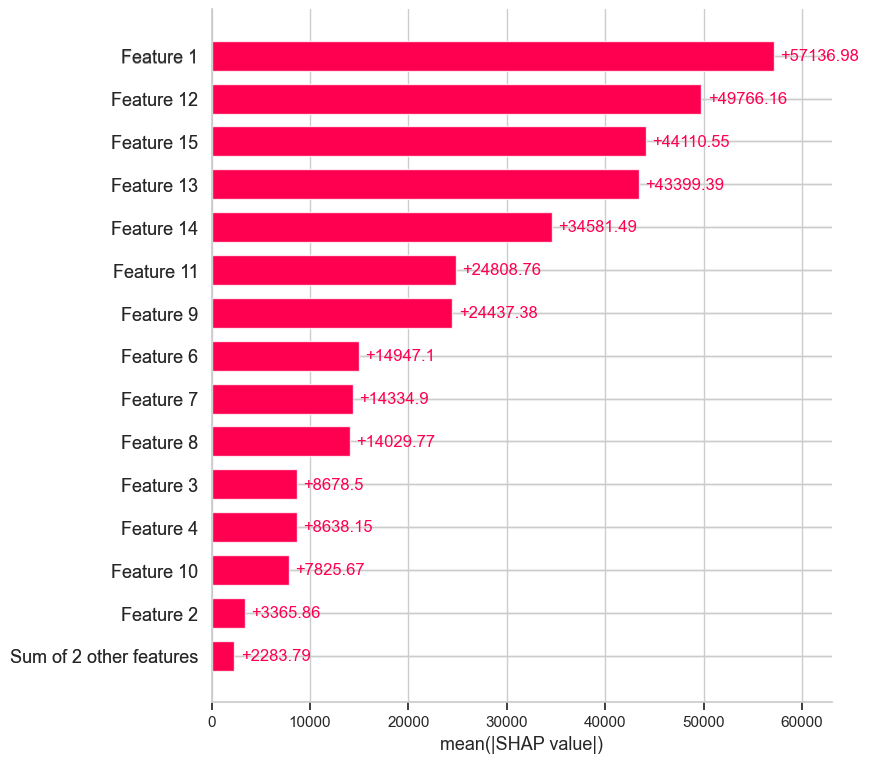

['num__year']


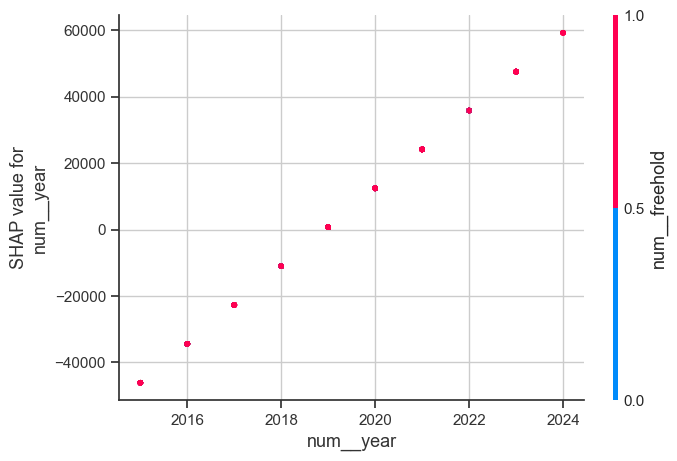

In [29]:
import numpy as np
import shap
import matplotlib.pyplot as plt

# Extract preprocessor and the trained linear model from the pipeline
preproc    = lin_pipe.named_steps['prep']
lin_model  = lin_pipe.named_steps['reg']   # sklearn.linear_model.LinearRegression

# Transform data exactly as during training
Xtr = preproc.transform(X_train)
Xte = preproc.transform(X_test)

# Get feature names after preprocessing (handles one-hot columns)
try:
    feat_names = preproc.get_feature_names_out()
except AttributeError:  # older sklearn versions
    feat_names = np.array([f"feat_{i}" for i in range(Xtr.shape[1])])

# Build a SHAP LinearExplainer (best for linear models)
masker     = shap.maskers.Independent(Xtr)   # background consistent with transformed data
explainer  = shap.LinearExplainer(lin_model, masker=masker)

# Compute SHAP values on a subset for speed
sv = explainer(Xte[:500])   # sv is a shap.Explanation object

# Summary Plot (Global feature importance)
shap.summary_plot(sv.values, Xte[:500], feature_names=feat_names, show=True)

# Bar Plot (Mean absolute SHAP values)
shap.plots.bar(sv, max_display=15)

# --- Dependence Plot ---
# Find the correct transformed name for 'year'
print([f for f in feat_names if "year" in f])

# Example: if output shows ['num__year'], use that name:
shap.dependence_plot('num__year', sv.values, Xte[:500], feature_names=feat_names)

In [30]:
import numpy as np
import lime.lime_tabular

# --- Use the same objects you already have from the pipeline ---
preproc   = lin_pipe.named_steps['prep']
lin_model = lin_pipe.named_steps['reg']  # final LinearRegression

# Transform train/test with the pipeline's preprocessor
Xtr = preproc.transform(X_train)
Xte = preproc.transform(X_test)

# Feature names after preprocessing (handles one-hot columns)
try:
    feat_names = preproc.get_feature_names_out()
except AttributeError:
    feat_names = np.array([f"feat_{i}" for i in range(Xtr.shape[1])])

# Build LIME explainer on the *transformed* numeric training data
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.asarray(Xtr),
    feature_names=feat_names,
    mode="regression",
    discretize_continuous=True,
    kernel_width=3.0
)

# Choose one transformed test instance
i = 5  # any index in range(len(Xte))
instance = np.asarray(Xte[i])

# IMPORTANT: since we pass transformed data, use the FINAL MODEL's predict
exp = explainer_lime.explain_instance(
    data_row=instance,
    predict_fn=lin_model.predict,   # <-- not lin_pipe.predict
    num_features=10
)

# Show explanation
exp.show_in_notebook(show_table=True)
print(exp.as_list())

[('cat__property_type_label_Terraced <= 0.00', -498276.38507674646), ('cat__property_type_label_Semi-Detached <= 0.00', 203918.4777554098), ('cat__property_type_label_Other <= 0.00', 120923.31537427098), ('cat__property_type_label_Flat <= 0.00', 118735.61223668771), ('num__property_type <= 0.00', 104318.50508867504), ('0.00 < cat__property_type_label_Detached <= 1.00', -54962.66402224026), ('num__year > 2021.00', 52526.96062891227), ('num__district > 265.00', 30457.30834407983), ('num__town <= 247.00', 29749.131651730502), ('num__street <= 11270.75', -17374.232136395374)]


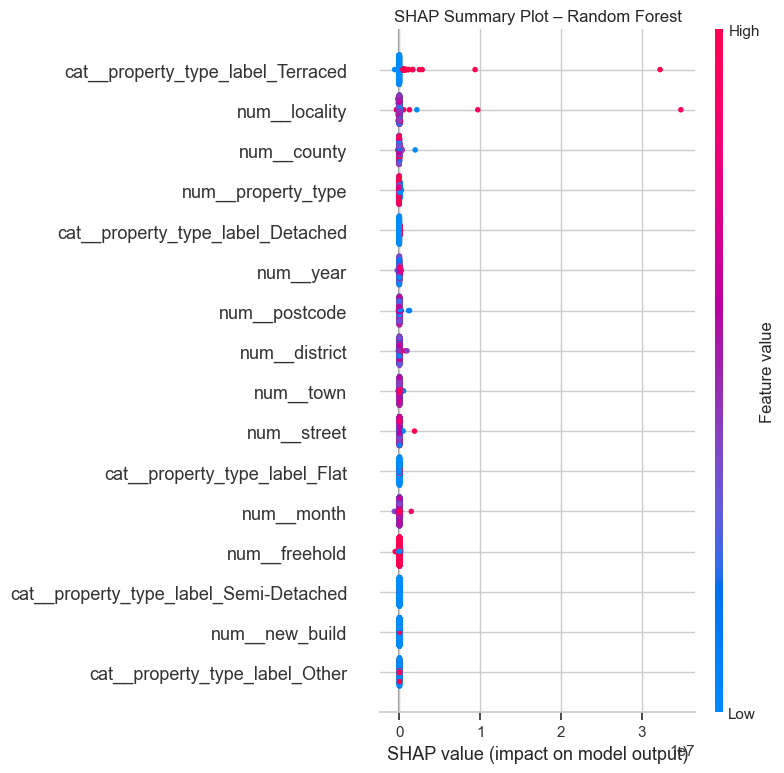

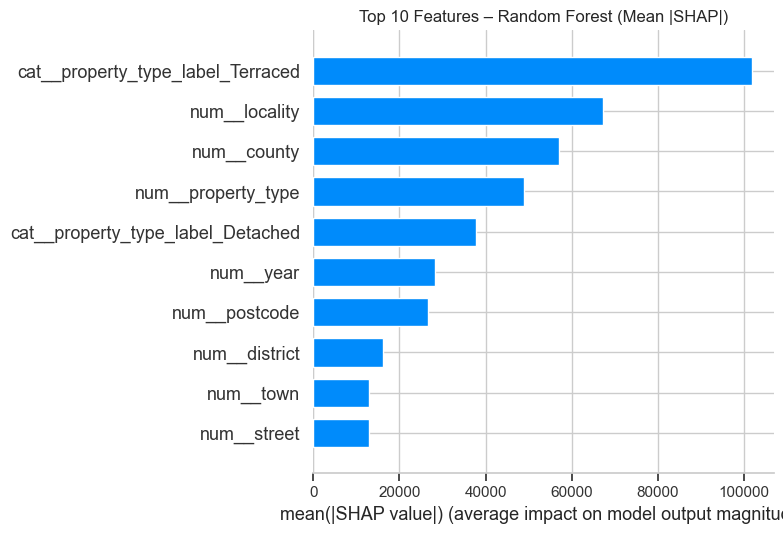

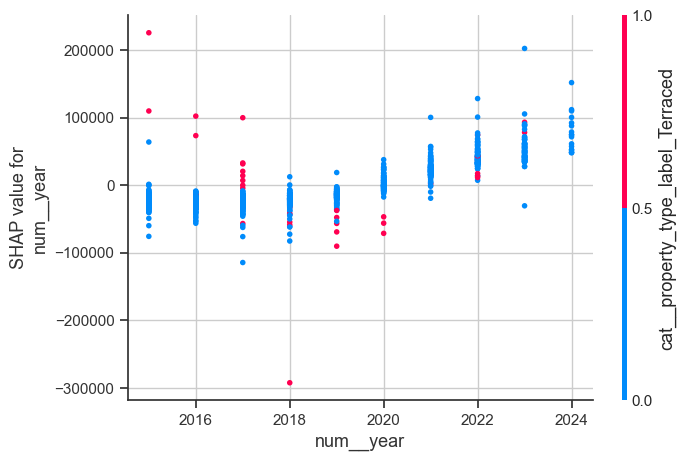

In [31]:
import numpy as np
import shap
import matplotlib.pyplot as plt

# 
preproc  = rf_pipe.named_steps['prep']          
rf_model = rf_pipe.named_steps['reg']           

# 
Xtr = preproc.transform(X_train)
Xte = preproc.transform(X_test)

# 
try:
    Xtr = Xtr.toarray()
    Xte = Xte.toarray()
except AttributeError:
    pass

# 
try:
    feat_names = preproc.get_feature_names_out()
except AttributeError:
    feat_names = np.array([f"feat_{i}" for i in range(Xte.shape[1])])

# 
explainer_shap = shap.TreeExplainer(rf_model)

# 
sv = explainer_shap.shap_values(Xte[:1000])   # shape: (n_samples, n_features) for regression

# 
plt.title("SHAP Summary Plot – Random Forest")
shap.summary_plot(sv, Xte[:1000], feature_names=feat_names, show=True)

plt.title("Top 10 Features – Random Forest (Mean |SHAP|)")
shap.summary_plot(sv, Xte[:1000], feature_names=feat_names,
                  plot_type="bar", max_display=10)

# 
year_cols = [n for n in feat_names if "year" in n]
if year_cols:
    shap.dependence_plot(year_cols[0], sv, Xte[:1000], feature_names=feat_names)

In [32]:
import numpy as np
import lime.lime_tabular

# 
preproc     = rf_pipe.named_steps['prep']
final_model = rf_pipe.named_steps['reg']   # RandomForestRegressor

# 
Xtr = preproc.transform(X_train)
Xte = preproc.transform(X_test)

# 
try:
    Xtr = Xtr.toarray()
    Xte = Xte.toarray()
except AttributeError:
    pass

# 
try:
    feat_names = preproc.get_feature_names_out()
except AttributeError:
    feat_names = np.array([f"feat_{k}" for k in range(Xtr.shape[1])])

# 
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=Xtr,
    feature_names=feat_names,
    mode="regression"
)

# 
i = 10  # any index from test set
exp = explainer.explain_instance(
    data_row=Xte[i],
    predict_fn=final_model.predict,   # use the Random Forest (not the pipeline)
    num_features=10
)

# 
exp.show_in_notebook(show_table=True)
print(exp.as_list())

[('cat__property_type_label_Terraced > 0.00', 1549475.7670599888), ('num__new_build <= 0.00', -316142.9339494092), ('num__year > 2021.00', 196873.33429120228), ('22576.50 < num__street <= 33110.25', 122092.75754581233), ('0.00 < num__property_type <= 3.00', -112947.57567630426), ('247.00 < num__town <= 508.00', 108179.25309118321), ('2510.00 < num__locality <= 4948.00', -96909.72209428028), ('18884.75 < num__postcode <= 37730.50', -82237.9177537466), ('cat__property_type_label_Semi-Detached <= 0.00', 67600.4987906563), ('num__district <= 75.00', -63594.4611763702)]


In [33]:
uk_house_clean.describe()

,price,postcode,property_type,new_build,freehold,street,locality,town,district,county,year,month
count,9.000000e+04,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000
mean,3.238753e+05,37680.316611,2.006111,0.123756,0.855489,22218.040156,5066.491800,483.395322,174.035722,60.656167,2019.034744,6.712533
std,1.282104e+06,21686.698449,1.636579,0.329304,0.351609,12499.900880,2947.307924,267.871552,106.821559,30.797670,2.565491,3.419289
min,1.000000e+02,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2015.000000,1.000000
25%,1.600000e+05,18892.000000,0.000000,0.000000,1.000000,11281.000000,2510.000000,245.000000,74.000000,37.000000,2017.000000,4.000000
50%,2.449950e+05,37749.500000,3.000000,0.000000,1.000000,22665.000000,4928.000000,507.000000,178.000000,55.000000,2019.000000,7.000000
75%,3.651588e+05,56401.250000,3.000000,0.000000,1.000000,33160.250000,7584.000000,694.000000,265.000000,87.000000,2021.000000,10.000000
max,3.000000e+08,75322.000000,4.000000,1.000000,1.000000,43482.000000,10144.000000,957.000000,358.000000,116.000000,2024.000000,12.000000


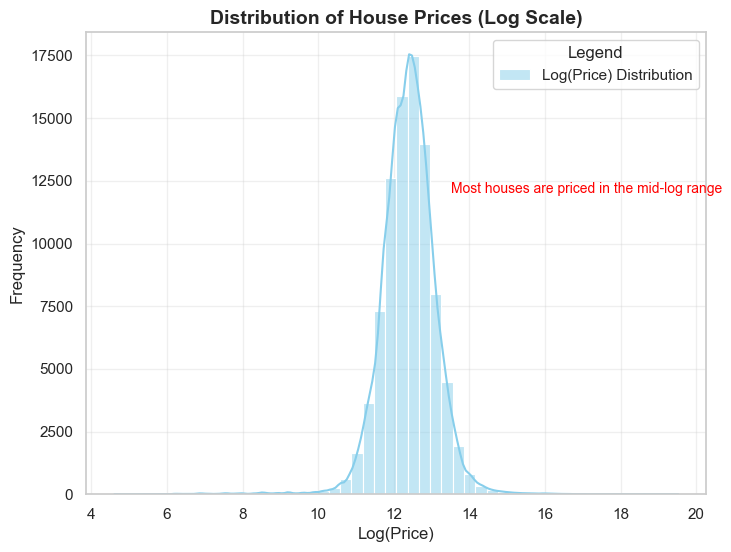

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.figure(figsize=(8,6))
sns.histplot(np.log1p(uk_house_clean['price']), bins=50, kde=True, color="skyblue", label="Log(Price) Distribution")
plt.title("Distribution of House Prices (Log Scale)", fontsize=14, fontweight="bold")
plt.xlabel("Log(Price)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(alpha=0.3)

# Add legend
plt.legend(title="Legend", loc="upper right")

# Add annotation to explain
plt.text(13.5, 12000, "Most houses are priced in the mid-log range", fontsize=10, color="red")

plt.show()

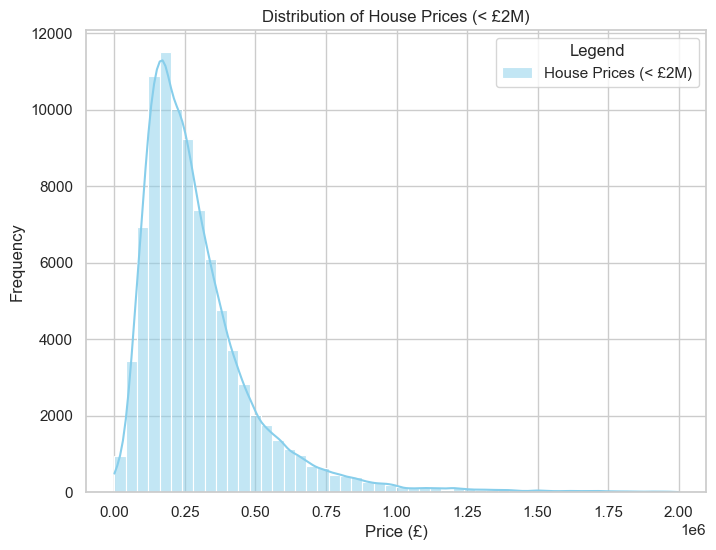

In [35]:
plt.figure(figsize=(8,6))
sns.histplot(uk_house_clean[uk_house_clean['price'] < 2_000_000]['price'], 
             bins=50, kde=True, color="skyblue", label="House Prices (< £2M)")
plt.title("Distribution of House Prices (< £2M)")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")
plt.legend(title="Legend")
plt.show()

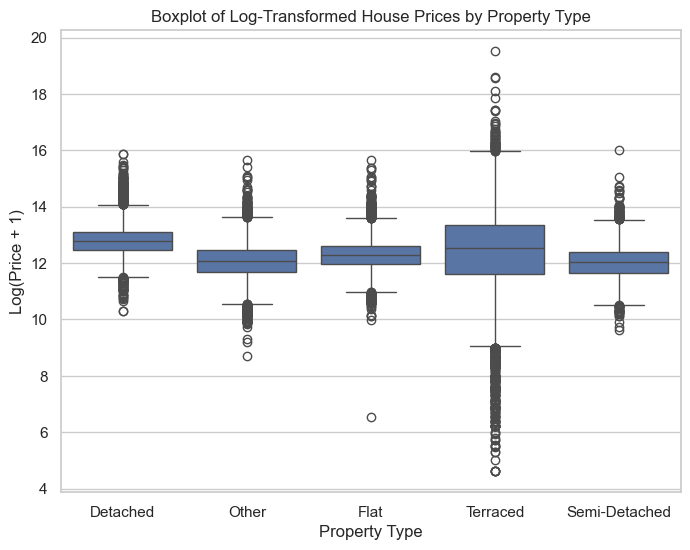

In [39]:
import numpy as np

# Add log-transformed column
uk_house_clean['log_price'] = np.log1p(uk_house_clean['price'])

plt.figure(figsize=(8,6))
sns.boxplot(x='property_type_label', y='log_price', data=uk_house_clean)

plt.title("Boxplot of Log-Transformed House Prices by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Log(Price + 1)")
plt.show()